In [1]:
import pandas as pd
import numpy as np
import os
from glob import glob
from sklearn.metrics import roc_curve, auc, balanced_accuracy_score
import matplotlib.pyplot as plt

#from matplotlib import rcParams
#rcParams['font.family'] = 'serif'
#rcParams['text.usetex'] = 'true'
#rcParams['font.size'] = 16

from IPython.display import Markdown, display

In [2]:

#========== FUNCTIONS TO PRINT SCORES ==========#


def compute_metrics(labels, pred):
    
    fpr, tpr, thres = roc_curve(labels, pred)
    rocauc = auc(fpr, tpr)
    fnr = 1 - tpr
    eer = fpr[np.nanargmin(np.absolute(fnr - fpr))]
    
    #optimal_index = np.argmax(tpr - fpr)
    #optimal_threshold = thres[optimal_index]

    binary_pred = np.where(pred < -0.5, 0, 1)    
    acc = balanced_accuracy_score(labels, binary_pred)
    
    return rocauc, eer, acc
    
def printmd(string):
    display(Markdown(string))

def print_results(model_names, dataset_list):
    if isinstance(model_names, str):
        model_names = [model_names]

    all_scores = {}

    for dataset in dataset_list:
        dataset_name = os.path.basename(dataset)
        output = f"### {dataset_name.upper()} DATASET\n\n"
        scores = []

        for model_name in model_names:
            result_list = glob(os.path.join(dataset, f"{model_name}.txt"))

            for result in result_list:
                df = pd.read_csv(result, header=None, sep=' ')
                df = df.rename(columns={0: 'path', 1: 'score', 2: 'label'})

                rocauc, eer, bal_acc = compute_metrics(df['label'], df['score']) 

                exp_name = os.path.basename(result)[:-4]
                scores.append({
                    'name': exp_name,
                    'auc': rocauc,
                    'eer': eer,
                    'bal_acc': bal_acc
                })

                if exp_name not in all_scores:
                    all_scores[exp_name] = []
                all_scores[exp_name].append({
                    'dataset': dataset_name,
                    'auc': rocauc,
                    'eer': eer,
                    'bal_acc': bal_acc
                })

        # Best scores
        best_auc = max(scores, key=lambda x: x['auc'])['auc']
        best_eer = min(scores, key=lambda x: x['eer'])['eer']
        best_bal_acc = max(scores, key=lambda x: x['bal_acc'])['bal_acc']

        for s in scores:
            name = s['name']
            auc = s['auc']
            eer = s['eer']
            bal_acc = s['bal_acc']

            auc_str = f"**{auc*100:.2f}**" if auc == best_auc else f"{auc*100:.2f}"
            eer_str = f"**{eer*100:.2f}**" if eer == best_eer else f"{eer*100:.2f}"
            bal_str = f"**{bal_acc*100:.2f}**" if bal_acc == best_bal_acc else f"{bal_acc*100:.2f}"

            output += f"`{name}`\t AUC: {auc_str} \t EER: {eer_str} \t Balanced Acc: {bal_str}\n\n"

        printmd(output)

    return all_scores
        
def print_results_NO_BACC(model_names, dataset_list):
    if isinstance(model_names, str):
        model_names = [model_names]

    #dataset_list = glob('/nas/home/vnegroni/ispl_safe/results/*')
    all_scores = {}  # Store results in a dictionary

    for dataset in dataset_list:
        dataset_name = os.path.basename(dataset)
        output = f"### {dataset_name.upper()} DATASET\n\n"
        scores = []

        for model_name in model_names:
            result_list = glob(os.path.join(dataset, f"{model_name}.txt"))

            for result in result_list:
                df = pd.read_csv(result, header=None, sep=' ')
                df = df.rename(columns={0: 'path', 1: 'score', 2: 'label'})

                rocauc, eer, bal_acc = compute_metrics(df['label'], df['score'])

                exp_name = os.path.basename(result)[:-4]
                scores.append({
                    'name': exp_name,
                    'auc': rocauc,
                    'eer': eer
                })

                # Save to the main dictionary
                if exp_name not in all_scores:
                    all_scores[exp_name] = []
                all_scores[exp_name].append({
                    'dataset': dataset_name,
                    'auc': rocauc,
                    'eer': eer
                })

        best_auc = max(scores, key=lambda x: x['auc'])['auc']
        best_eer = min(scores, key=lambda x: x['eer'])['eer']

        for s in scores:
            name = s['name']
            auc = s['auc']
            eer = s['eer']

            auc_str = f"**{auc*100:.2f}**" if auc == best_auc else f"{auc*100:.2f}"
            eer_str = f"**{eer*100:.2f}**" if eer == best_eer else f"{eer*100:.2f}"

            output += f"`{name}`\t AUC: {auc_str} \t EER: {eer_str}\n\n"

        printmd(output)

    return all_scores


def print_average_results_by_type(all_scores, known_datasets, subset='overall'):
    if subset not in ('known', 'unknown', 'overall'):
        raise ValueError("subset must be 'known', 'unknown', or 'overall'")

    output = f"## AVERAGE METRICS - {subset.upper()}\n\n"
    avg_scores = []

    for model, entries in all_scores.items():
        if subset == 'known':
            filtered = [e for e in entries if e['dataset'] in known_datasets]
        elif subset == 'unknown':
            filtered = [e for e in entries if e['dataset'] not in known_datasets]
        else:
            filtered = entries

        aucs = [e['auc'] for e in filtered]
        eers = [e['eer'] for e in filtered]
        bals = [e['bal_acc'] for e in filtered]

        avg_auc = np.mean(aucs) if aucs else None
        avg_eer = np.mean(eers) if eers else None
        avg_bal = np.mean(bals) if bals else None

        avg_scores.append({
            'model': model,
            'avg_auc': avg_auc,
            'avg_eer': avg_eer,
            'avg_bal': avg_bal
        })

    # Best values
    best_auc = max((s['avg_auc'] for s in avg_scores if s['avg_auc'] is not None), default=None)
    best_eer = min((s['avg_eer'] for s in avg_scores if s['avg_eer'] is not None), default=None)
    best_bal = max((s['avg_bal'] for s in avg_scores if s['avg_bal'] is not None), default=None)

    def fmt(value, best_value, is_best_fmt=True):
        if value is None:
            return "N/A"
        s = f"{value*100:.2f}"
        return f"**{s}**" if is_best_fmt and value == best_value else s

    for s in avg_scores:
        model = s['model']
        auc_str = fmt(s['avg_auc'], best_auc)
        eer_str = fmt(s['avg_eer'], best_eer)
        bal_str = fmt(s['avg_bal'], best_bal)

        output += f"`{model}`\t Avg AUC: {auc_str} \t Avg EER: {eer_str} \t Avg Balanced Acc: {bal_str}\n\n"

    printmd(output)

    
def print_average_results_by_type_NO_BACC(all_scores, known_datasets, subset='overall'):
    """
    subset: one of 'known', 'unknown', 'overall'
    """

    if subset not in ('known', 'unknown', 'overall'):
        raise ValueError("subset must be 'known', 'unknown', or 'overall'")

    output = f"## AVERAGE METRICS - {subset.upper()}\n\n"
    avg_scores = []

    for model, entries in all_scores.items():
        # Filter by subset
        if subset == 'known':
            filtered = [e for e in entries if e['dataset'] in known_datasets]
        elif subset == 'unknown':
            filtered = [e for e in entries if e['dataset'] not in known_datasets]
        else:  # overall
            filtered = entries

        aucs = [e['auc'] for e in filtered]
        eers = [e['eer'] for e in filtered]

        if not aucs:
            avg_auc = None
            avg_eer = None
        else:
            avg_auc = np.mean(aucs)
            avg_eer = np.mean(eers)

        avg_scores.append({
            'model': model,
            'avg_auc': avg_auc,
            'avg_eer': avg_eer
        })

    # Get best scores for formatting (highest AUC, lowest EER)
    best_auc = max((s['avg_auc'] for s in avg_scores if s['avg_auc'] is not None), default=None)
    best_eer = min((s['avg_eer'] for s in avg_scores if s['avg_eer'] is not None), default=None)

    def fmt(value, best_value, is_best_fmt=True):
        if value is None:
            return "N/A"
        s = f"{value*100:.2f}"
        return f"**{s}**" if is_best_fmt and value == best_value else s

    for s in avg_scores:
        model = s['model']
        auc_str = fmt(s['avg_auc'], best_auc)
        eer_str = fmt(s['avg_eer'], best_eer, is_best_fmt=True)

        output += f"`{model}`\t Avg AUC: {auc_str} \t Avg EER: {eer_str}\n\n"

    printmd(output)



#========== FUNCTIONS TO PLOT GATING WEIGHTS ==========#
    

def plot_expert_weights_spoof(
    results_root,
    npy_files,               # <-- list of npy files (one per row)
    num_experts=4,
    max_datasets=4,
    figsize=(16, 3),
    expert_labels=None,
    hline=0.5
):
    assert isinstance(npy_files, (list, tuple)), "npy_files must be a list"

    dataset_list = glob(os.path.join(results_root, '*'))
    n_rows = len(npy_files)

    fig, axes = plt.subplots(
        n_rows,
        max_datasets,
        figsize=(figsize[0], figsize[1] * n_rows),
        squeeze=False
    )

    if expert_labels is None:
        expert_labels = [f'E_{i}' for i in range(num_experts)]

    for row_idx, npy_name in enumerate(npy_files):
        used_axes = 0

        for col_idx, dataset in enumerate(dataset_list[:max_datasets]):

            dataset_name = os.path.basename(dataset).upper()
            weights_path = os.path.join(dataset, npy_name)

            ax = axes[row_idx, col_idx]

            if not os.path.exists(weights_path):
                print(f'[WARN] Missing file: {weights_path}')
                ax.set_visible(False)
                continue

            expert_weights = np.load(weights_path)

            if expert_weights.ndim > 1 and expert_weights.shape[1] > 1:
                expert_weights = expert_weights[:, 1]

            if expert_weights.size != num_experts:
                print(
                    f'[WARN] {dataset_name} / {npy_name}: '
                    f'expected {num_experts}, got {expert_weights.size}\n'
                    f'path={weights_path}\n'
                    f'shape={expert_weights.shape}, dtype={expert_weights.dtype}\n'
                )
                ax.set_visible(False)
                continue

            expert_weights = expert_weights.flatten()

            colors = ['tab:blue'] * num_experts
            highlight_expert = col_idx % num_experts
            colors[highlight_expert] = 'green'

            ax.bar(
                range(num_experts),
                expert_weights,
                tick_label=expert_labels,
                color=colors
            )

            if hline is not None:
                ax.axhline(y=hline, color='red', linestyle='--', zorder=4)

            ax.set_title(f'{dataset_name}')
            #ax.set_xlabel('Experts')
            ax.set_xlabel(
                f"Experts, {[f'{w:.2f}' for w in expert_weights]}"
            )            
            ax.set_ylabel('Avg Gating Weight')
            ax.set_ylim(0, 1)
            ax.grid(True)
            ax.set_axisbelow(True)

            used_axes += 1

        # Remove unused columns in this row
        for j in range(used_axes, max_datasets):
            fig.delaxes(axes[row_idx, j])

        # Row label on the left
        axes[row_idx, 0].set_ylabel(f'{npy_name}\nAvg Gating Weight')

    plt.tight_layout()
    plt.show()


def plot_expert_weights_bonafide(
    results_root,
    npy_list,
    num_experts=4,
    figsize=(16, 3),
    expert_labels=None,
    hline=0.5
):
    #npy_list = sorted(glob(os.path.join(results_root, '*.npy')))
    npy_list = [os.path.join(results_root, p) for p in npy_list]
    n_cols = len(npy_list)

    if n_cols == 0:
        raise ValueError("No .npy files found in results_root")

    fig, axes = plt.subplots(
        1, n_cols,
        figsize=figsize,
        squeeze=False
    )

    if expert_labels is None:
        expert_labels = [f'E_{i}' for i in range(num_experts)]

    for col_idx, npy_name in enumerate(npy_list):
        ax = axes[0, col_idx]

        dataset_name = os.path.splitext(os.path.basename(npy_name))[0]
        expert_weights = np.load(npy_name)

        # If shape is (N, 2) or similar, take column 1
        if expert_weights.ndim > 1:
            if expert_weights.shape[1] > 1:
                expert_weights = expert_weights[:, 1]
                #print(f'[INFO] Sliced expert_weights for {dataset_name}')

        expert_weights = expert_weights.flatten()

        if expert_weights.size != num_experts:
            print(
                f'[WARN] {dataset_name}: expected {num_experts}, '
                f'got {expert_weights.size}'
            )
            ax.set_visible(False)
            continue

        ax.bar(
            range(num_experts),
            expert_weights,
            tick_label=expert_labels,
            color=['tab:pink'] * num_experts
        )

        if hline is not None:
            ax.axhline(y=hline, color='red', linestyle='--', zorder=4)

        ax.set_title(dataset_name)
        ax.set_xlabel(
            f"Experts ({', '.join(f'{w:.2f}' for w in expert_weights)})"
        )

        if col_idx == 0:
            ax.set_ylabel('Avg Gating Weight')

        ax.set_ylim(0, 1)
        ax.grid(True)
        ax.set_axisbelow(True)

    plt.tight_layout()
    plt.show()



#========== FUNCTIONS FOR SANITY CHECKS ==========#


def inspect_npy(npy_path, max_print=10):
    data = np.load(npy_path)

    print(f"\nFile: {os.path.basename(npy_path)}")
    print(f"Original shape: {data.shape}")
    print(f"Dtype: {data.dtype}")

    if data.ndim == 2 and data.shape[1] >= 2:
        print("[INFO] Showing column index 1")
        data_to_print = data[:, 1]
        print(f"Displayed shape: {data_to_print.shape}")
    else:
        data_to_print = data

    np.set_printoptions(precision=8, suppress=True)

    print("Values:")
    if data_to_print.size <= max_print:
        print(data_to_print)
    else:
        flat = data_to_print.flatten()
        print(flat[:max_print], "...")

    return data_to_print


def _normalize_expert_weights(data):
    """
    Normalize expert weights to shape (N,)
    Supported:
      - (N, 2) -> data[:, 1]
      - (N, 1) -> data[:, 0]
      - (N,)   -> data
    """
    data = np.asarray(data)

    if data.ndim == 2:
        if data.shape[1] == 2:
            return data[:, 1]
        elif data.shape[1] == 1:
            return data[:, 0]
        else:
            raise ValueError(f"Unsupported 2D shape: {data.shape}")

    if data.ndim == 1:
        return data

    raise ValueError(f"Unsupported shape: {data.shape}")



def check_identical_npy_within_dataset(
    results_root,
    npy_files,
    max_datasets=None,
    rtol=1e-5,
    atol=1e-8
):
    results_root = os.path.abspath(os.path.expanduser(results_root))
    print(f"[DEBUG] Using results_root = {results_root}")

    try:
        dataset_list = [
            entry.path
            for entry in os.scandir(results_root)
            if entry.is_dir()
        ]
    except FileNotFoundError:
        print(f"[ERROR] Directory does not exist: {results_root}")
        return {}

    if max_datasets is not None:
        dataset_list = dataset_list[:max_datasets]

    if not dataset_list:
        print(f"[ERROR] No dataset subfolders found in: {results_root}")
        return {}

    results = {}

    for dataset in dataset_list:
        dataset_name = os.path.basename(dataset)
        print(f"\nChecking dataset: {dataset_name}")

        reference = None
        identical = True

        for npy_name in npy_files:
            path = os.path.join(dataset, npy_name)

            if not os.path.exists(path):
                print(f"  [MISSING] {npy_name}")
                identical = False
                break

            raw = np.load(path)

            try:
                data = _normalize_expert_weights(raw)
            except ValueError as e:
                print(f"  [ERROR] {npy_name}: {e}")
                identical = False
                break

            if reference is None:
                reference = data
                print(f"  [REF] {npy_name} shape={raw.shape} → {data.shape}")
            else:
                if not np.allclose(reference, data, rtol=rtol, atol=atol):
                    print(f"  [DIFF] {npy_name}")
                    identical = False
                    break
                else:
                    print(f"  [OK]   {npy_name}")

        results[dataset_name] = identical
        print(f"  → RESULT: {'IDENTICAL' if identical else 'DIFFERENT'}")

    return results

# Performance Analysis

In [3]:
model_names = ["POC_MELE_CAT_FRZ", 
               "POC_MELE_CAT",
               "POC_MELE_TRANSF_FRZ",
               "POC_MELE_TRANSF"
              ]

dataset_list = [
    '/home/smg/v-viola/moe_antideepfake/results/POC/mixed',
]

results = print_results_NO_BACC(model_names, dataset_list)

### MIXED DATASET

`POC_MELE_CAT_FRZ`	 AUC: 99.98 	 EER: 0.25

`POC_MELE_CAT`	 AUC: **100.00** 	 EER: **0.00**

`POC_MELE_TRANSF_FRZ`	 AUC: 99.97 	 EER: 0.13

`POC_MELE_TRANSF`	 AUC: **100.00** 	 EER: **0.00**



# Gating Weights Analysis

## Pseudo-fakes Data Only
- **First row:** Weights × Probability
- **Second row:** Weights only
- **Columns:** Mini-datasets 

### Frozen Models

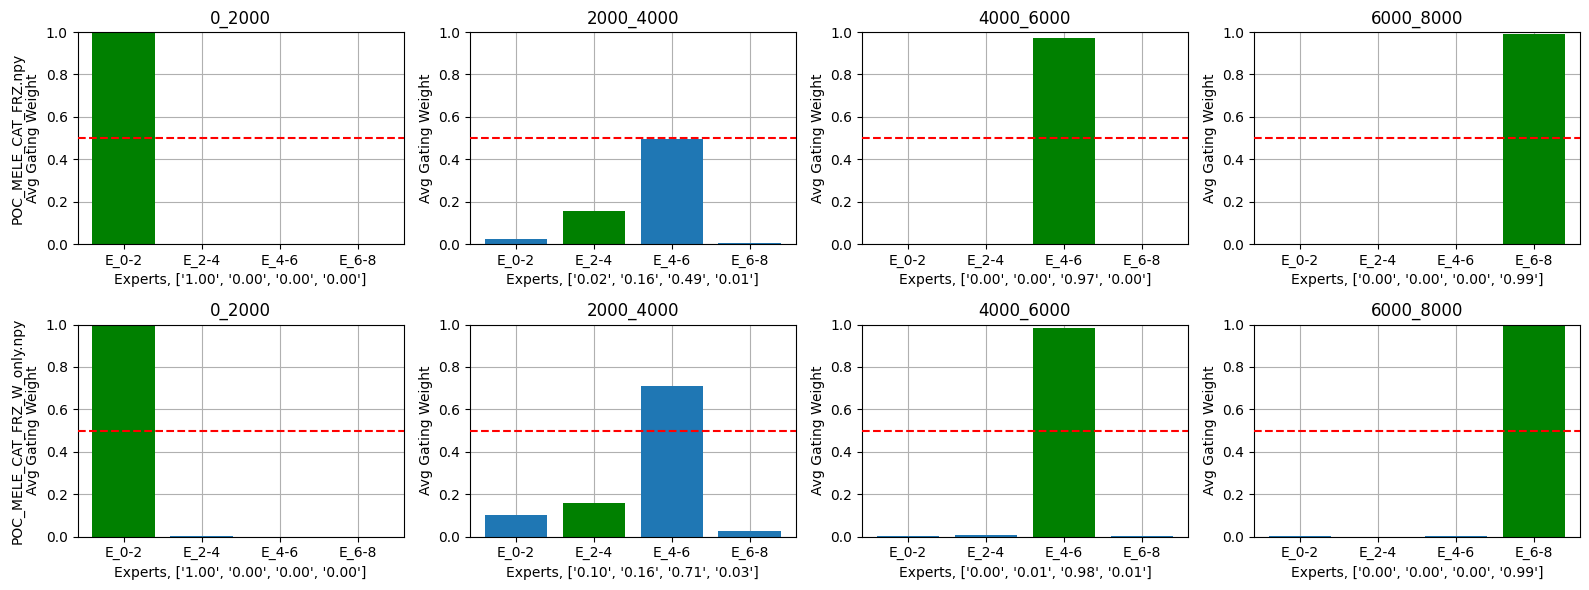

In [4]:
plot_expert_weights_spoof(
    results_root='/home/smg/v-viola/moe_antideepfake/results/POC/spoof',
    npy_files=['POC_MELE_CAT_FRZ.npy', 'POC_MELE_CAT_FRZ_W_only.npy'],
    num_experts=4,
    expert_labels=['E_0-2', 'E_2-4', 'E_4-6', 'E_6-8']
)

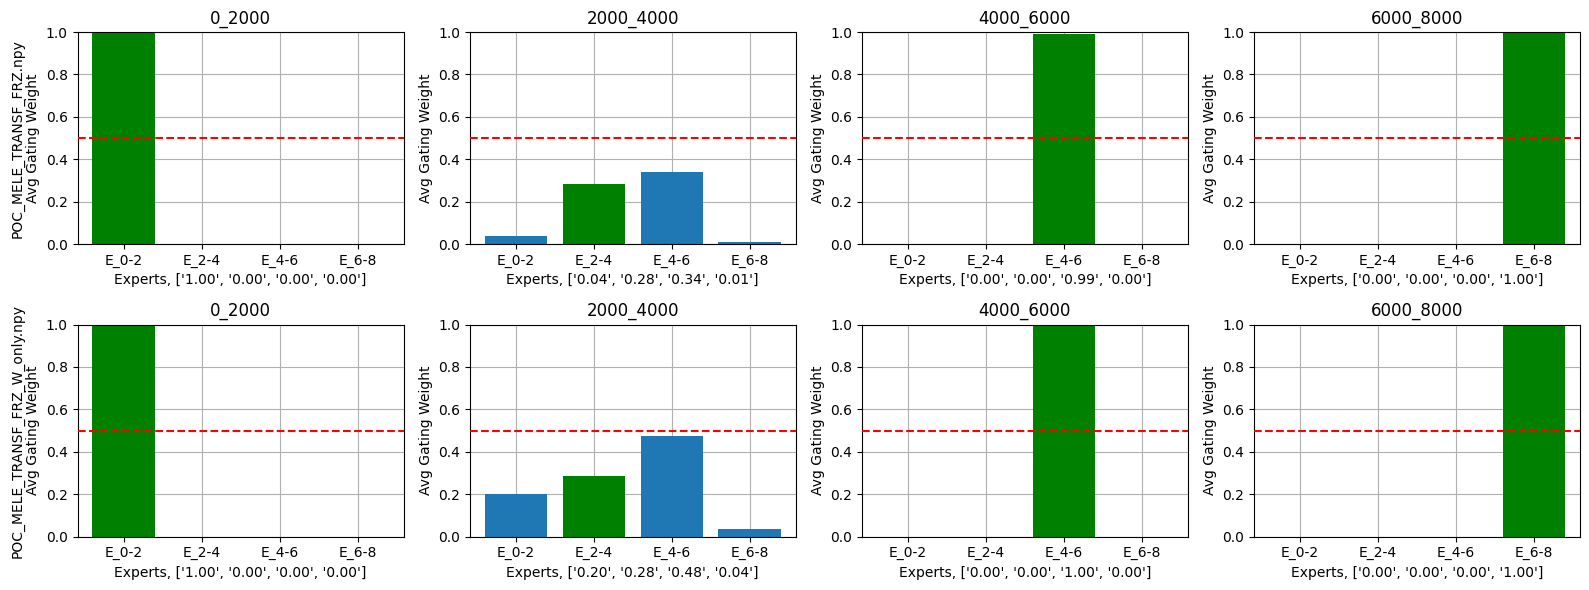

In [5]:
plot_expert_weights_spoof(
    results_root='/home/smg/v-viola/moe_antideepfake/results/POC/spoof',
    npy_files=['POC_MELE_TRANSF_FRZ.npy', 'POC_MELE_TRANSF_FRZ_W_only.npy'],
    num_experts=4,
    expert_labels=['E_0-2', 'E_2-4', 'E_4-6', 'E_6-8']
)

### Unfrozen models

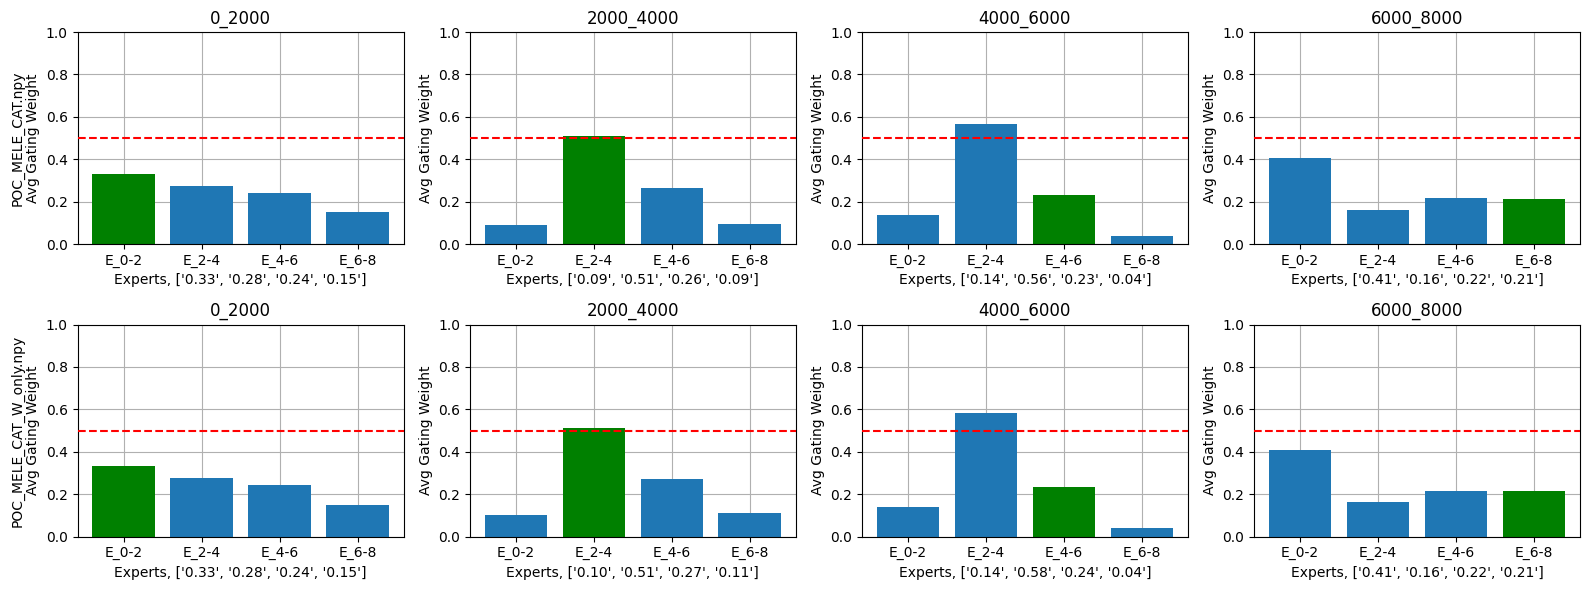

In [6]:
plot_expert_weights_spoof(
    results_root='/home/smg/v-viola/moe_antideepfake/results/POC/spoof',
    npy_files=['POC_MELE_CAT.npy', 'POC_MELE_CAT_W_only.npy'],
    num_experts=4,
    expert_labels=['E_0-2', 'E_2-4', 'E_4-6', 'E_6-8']
)

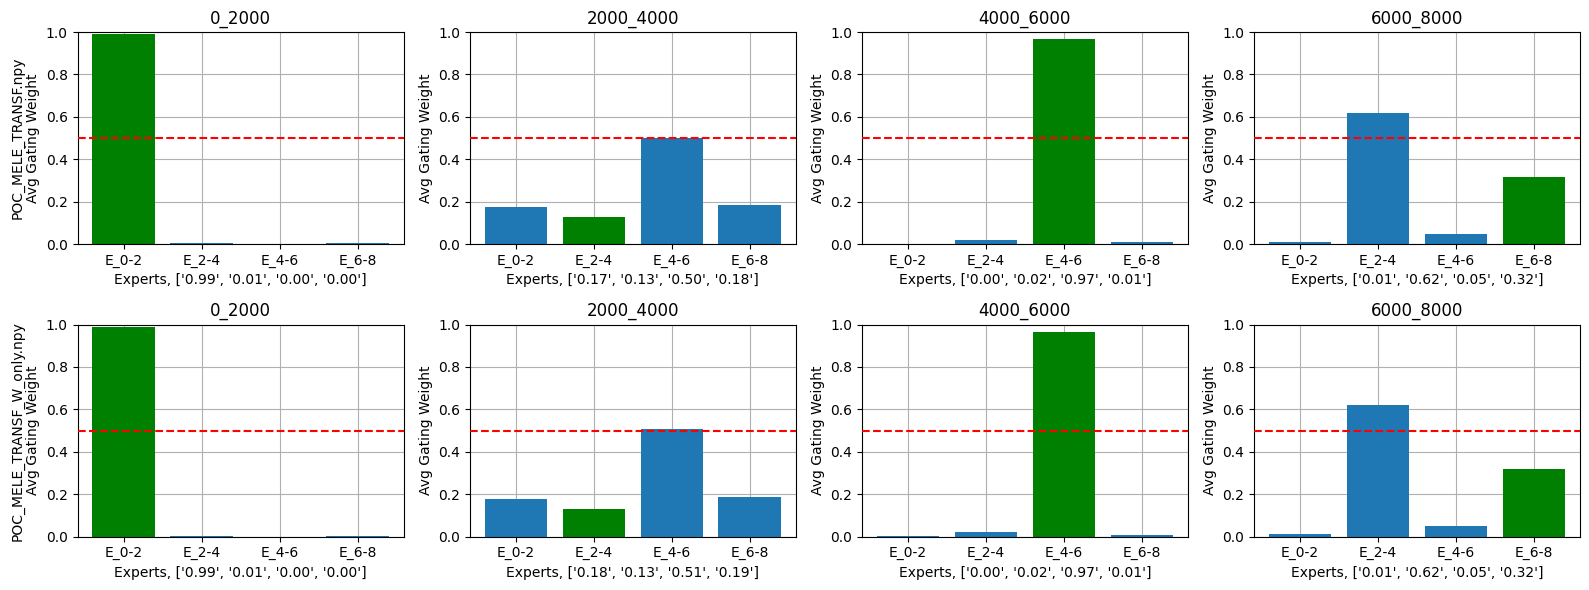

In [7]:
plot_expert_weights_spoof(
    results_root='/home/smg/v-viola/moe_antideepfake/results/POC/spoof',
    npy_files=['POC_MELE_TRANSF.npy', 'POC_MELE_TRANSF_W_only.npy'],
    num_experts=4,
    expert_labels=['E_0-2', 'E_2-4', 'E_4-6', 'E_6-8']
)

## Sanity check (Ignore)

In [8]:
results = check_identical_npy_within_dataset(
    results_root="~/moe_antideepfake/results/POC/spoof",
    npy_files=['POC_MELE_TRANSF.npy', 'POC_MELE_TRANSF_W_only.npy']
)


[DEBUG] Using results_root = /home/smg/v-viola/moe_antideepfake/results/POC

Checking dataset: 0_2000
  [REF] POC_MELE_TRANSF.npy shape=(4, 2) → (4,)
  [DIFF] POC_MELE_TRANSF_W_only.npy
  → RESULT: DIFFERENT

Checking dataset: 2000_4000
  [REF] POC_MELE_TRANSF.npy shape=(4, 2) → (4,)
  [DIFF] POC_MELE_TRANSF_W_only.npy
  → RESULT: DIFFERENT

Checking dataset: 4000_6000
  [REF] POC_MELE_TRANSF.npy shape=(4, 2) → (4,)
  [DIFF] POC_MELE_TRANSF_W_only.npy
  → RESULT: DIFFERENT

Checking dataset: 6000_8000
  [REF] POC_MELE_TRANSF.npy shape=(4, 2) → (4,)
  [DIFF] POC_MELE_TRANSF_W_only.npy
  → RESULT: DIFFERENT

Checking dataset: bonafide
  [REF] POC_MELE_TRANSF.npy shape=(4, 2) → (4,)
  [DIFF] POC_MELE_TRANSF_W_only.npy
  → RESULT: DIFFERENT

Checking dataset: mixed
  [MISSING] POC_MELE_TRANSF.npy
  → RESULT: DIFFERENT


## Bonafide Data Only

- **Columns:** Different MoE Models

### Weights * Probability

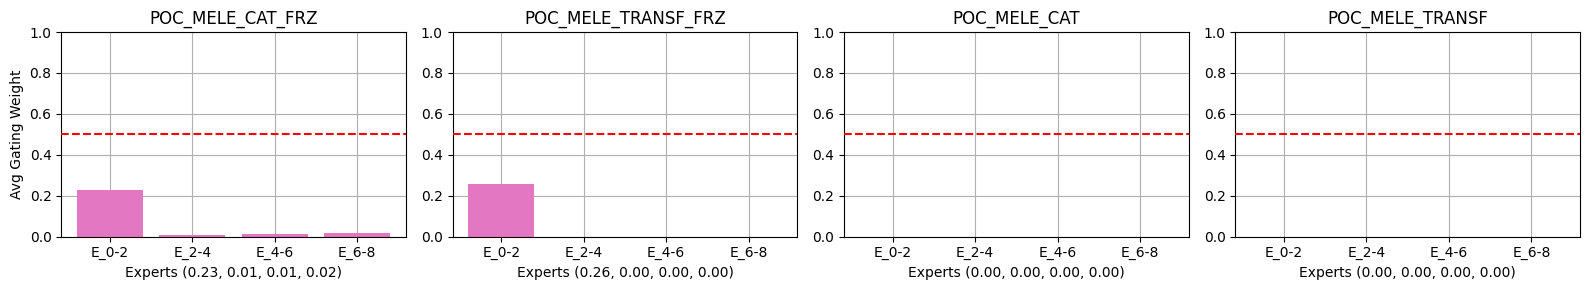

In [9]:
plot_expert_weights_bonafide(
    results_root='/home/smg/v-viola/moe_antideepfake/results/POC/bonafide',
    npy_list= ['POC_MELE_CAT_FRZ.npy', 
               'POC_MELE_TRANSF_FRZ.npy', 
               'POC_MELE_CAT.npy', 
               'POC_MELE_TRANSF.npy'],
    num_experts=4,
    expert_labels=['E_0-2', 'E_2-4', 'E_4-6', 'E_6-8']
)

### Weights Only

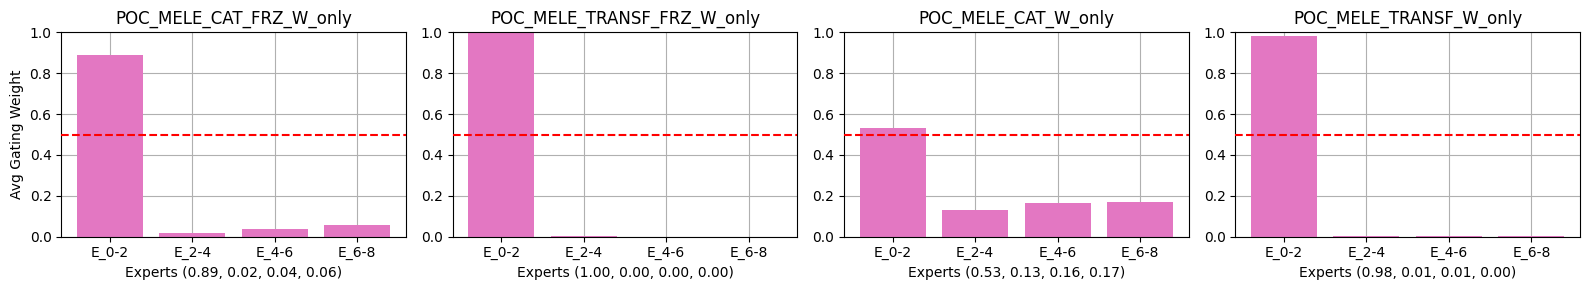

In [10]:
plot_expert_weights_bonafide(
    results_root='/home/smg/v-viola/moe_antideepfake/results/POC/bonafide',
    npy_list= ['POC_MELE_CAT_FRZ_W_only.npy', 
               'POC_MELE_TRANSF_FRZ_W_only.npy', 
               'POC_MELE_CAT_W_only.npy', 
               'POC_MELE_TRANSF_W_only.npy'],
    num_experts=4,
    expert_labels=['E_0-2', 'E_2-4', 'E_4-6', 'E_6-8']
)

## Sanity Check (Ignore)

In [11]:
for npy in glob('/home/smg/v-viola/moe_antideepfake/results/POC/bonafide/*.npy'):
    inspect_npy(npy)


File: POC_MELE_CAT_FRZ.npy
Original shape: (4, 2)
Dtype: float32
[INFO] Showing column index 1
Displayed shape: (4,)
Values:
[0.22671999 0.00600247 0.01294897 0.01846904]

File: POC_MELE_CAT.npy
Original shape: (4, 2)
Dtype: float32
[INFO] Showing column index 1
Displayed shape: (4,)
Values:
[0.00001685 0.00000377 0.00000349 0.0000036 ]

File: POC_MELE_TRANSF_FRZ.npy
Original shape: (4, 2)
Dtype: float32
[INFO] Showing column index 1
Displayed shape: (4,)
Values:
[0.25591987 0.00105508 0.00012365 0.00000925]

File: POC_MELE_TRANSF.npy
Original shape: (4, 2)
Dtype: float32
[INFO] Showing column index 1
Displayed shape: (4,)
Values:
[0.0000174  0.00000057 0.00000117 0.00000069]

File: POC_MELE_CAT_FRZ_W_only.npy
Original shape: (4, 1)
Dtype: float32
Values:
[[0.88707745]
 [0.01938918]
 [0.03711469]
 [0.05641876]]

File: POC_MELE_CAT_W_only.npy
Original shape: (4, 1)
Dtype: float32
Values:
[[0.5327778 ]
 [0.1318756 ]
 [0.16421372]
 [0.17113294]]

File: POC_MELE_TRANSF_FRZ_W_only.npy
Orig

# One-gender Data Only (Weights × Probability)

- **Order:**  
  - **First and second rows:** Frozen Models  
  - **Third and fourth rows:** Unfrozen Models


## Males

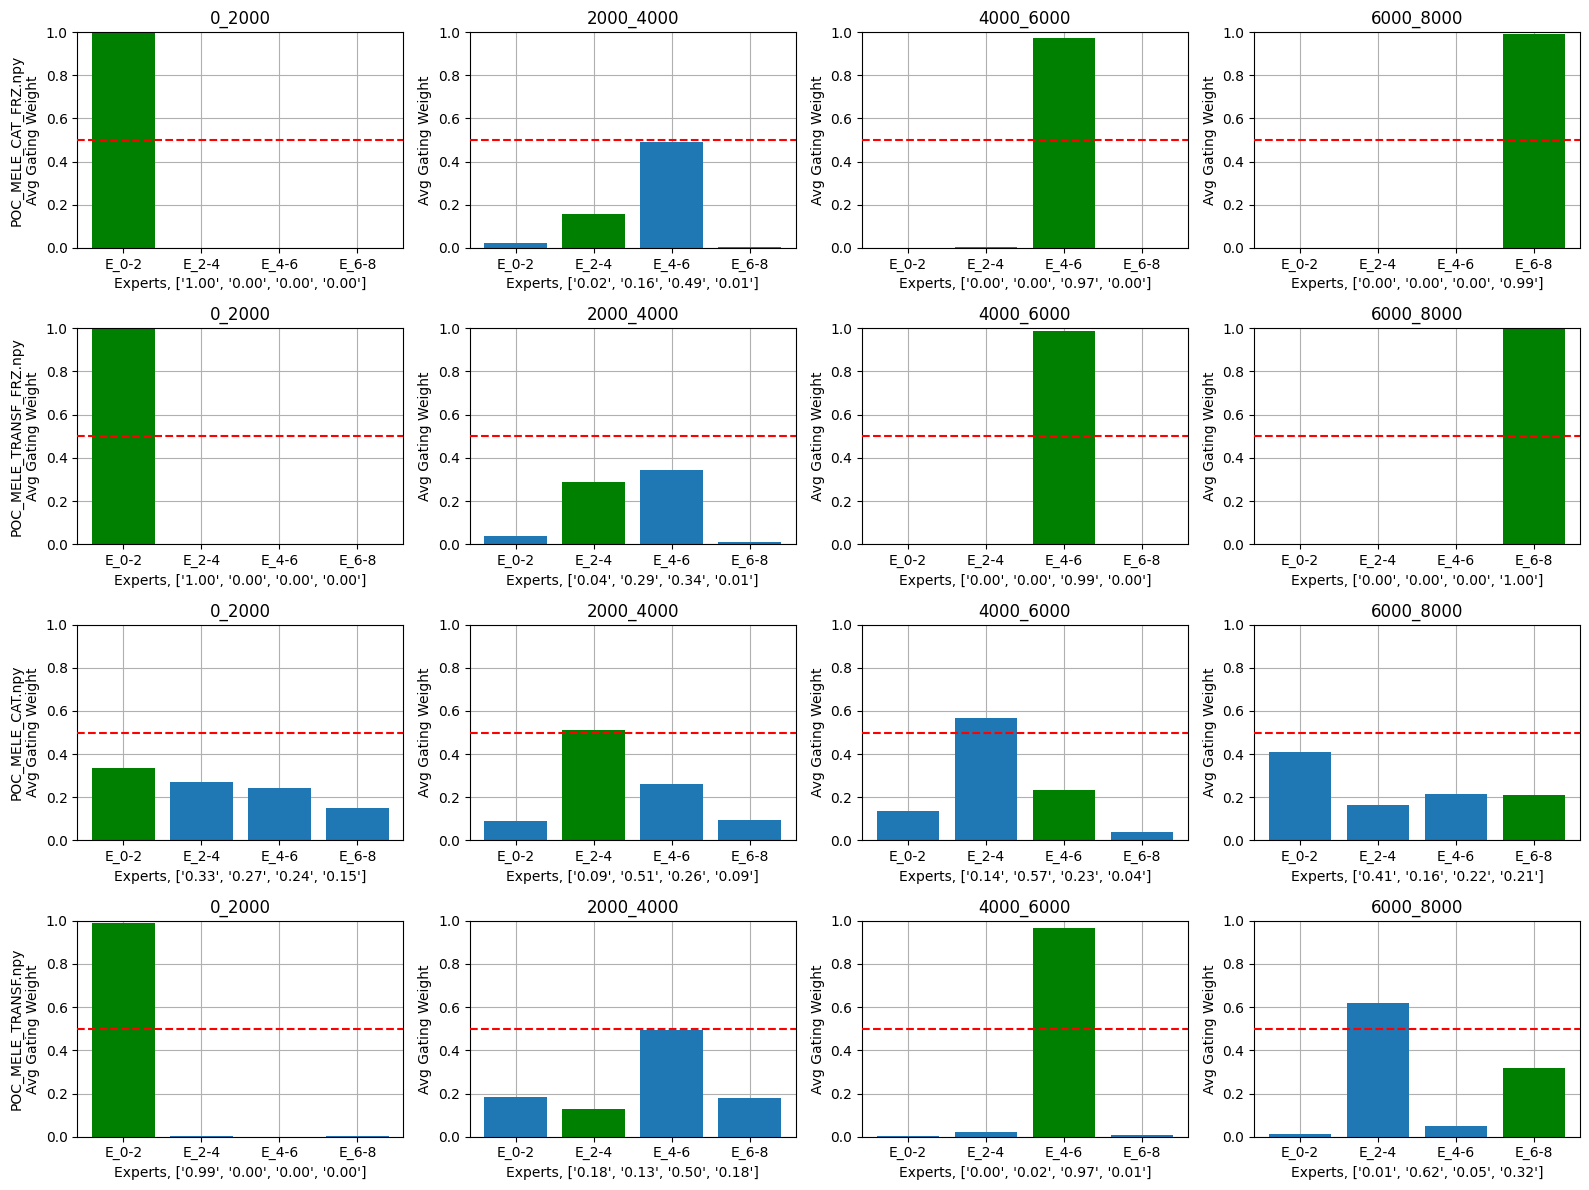

In [16]:
plot_expert_weights_spoof(
    results_root='/home/smg/v-viola/moe_antideepfake/results/POC/spoof/M-only',
    npy_files=['POC_MELE_CAT_FRZ.npy', 
               'POC_MELE_TRANSF_FRZ.npy', 
               'POC_MELE_CAT.npy', 
               'POC_MELE_TRANSF.npy'],
    num_experts=4,
    expert_labels=['E_0-2', 'E_2-4', 'E_4-6', 'E_6-8']
)

## Females

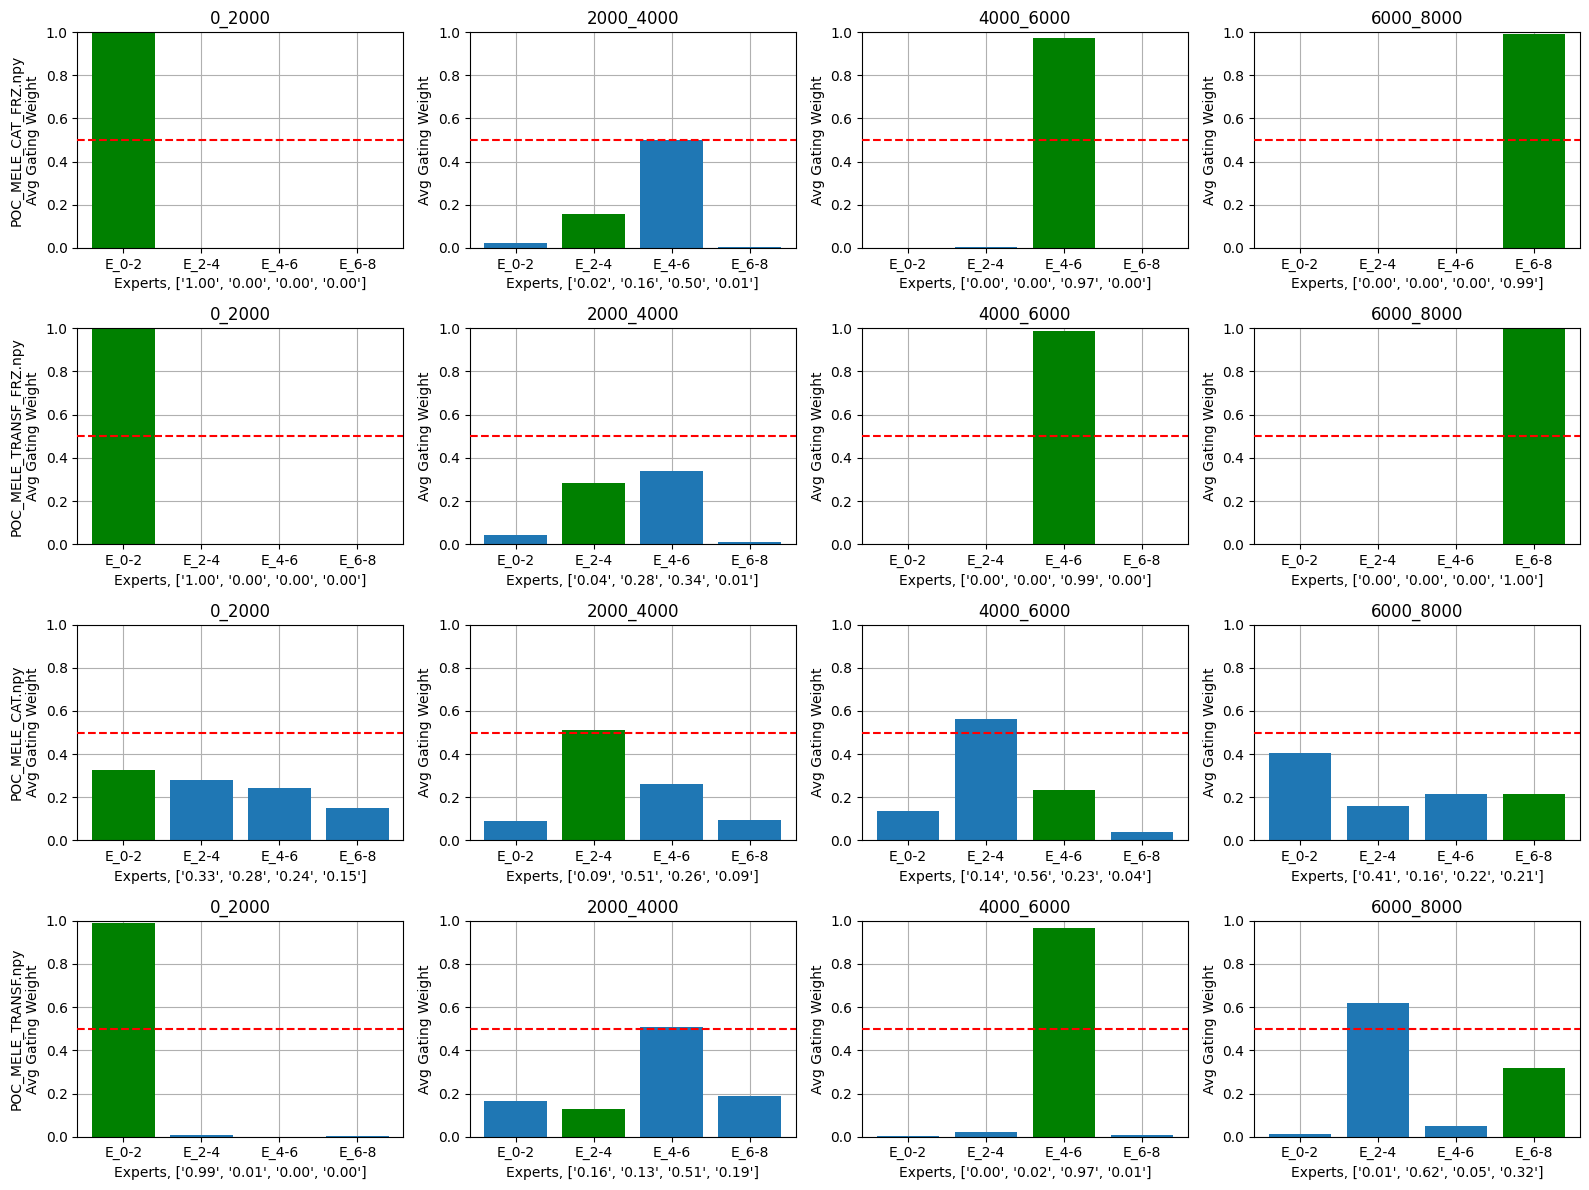

In [17]:
plot_expert_weights_spoof(
    results_root='/home/smg/v-viola/moe_antideepfake/results/POC/spoof/F-only',
    npy_files=['POC_MELE_CAT_FRZ.npy', 
               'POC_MELE_TRANSF_FRZ.npy', 
               'POC_MELE_CAT.npy', 
               'POC_MELE_TRANSF.npy'],
    num_experts=4,
    expert_labels=['E_0-2', 'E_2-4', 'E_4-6', 'E_6-8']
)